# Decision Trees and Random Forests in Python

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


## Load Data

In [2]:
df = pd.read_csv('./kyphosis.csv')

In [3]:
df.head()

,Kyphosis,Age,Number,Start
0,absent,71,3,5
1,absent,158,3,14
2,present,128,4,5
3,absent,2,5,1
4,absent,1,4,15


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   Kyphosis  81 non-null     object
 1   Age       81 non-null     int64 
 2   Number    81 non-null     int64 
 3   Start     81 non-null     int64 
dtypes: int64(3), object(1)
memory usage: 2.7+ KB


In [5]:
df.describe()

,Age,Number,Start
count,81.000000,81.000000,81.000000
mean,83.654321,4.049383,11.493827
std,58.104251,1.619423,4.883962
min,1.000000,2.000000,1.000000
25%,26.000000,3.000000,9.000000
50%,87.000000,4.000000,13.000000
75%,130.000000,5.000000,16.000000
max,206.000000,10.000000,18.000000


## Exploratory Data Analysis

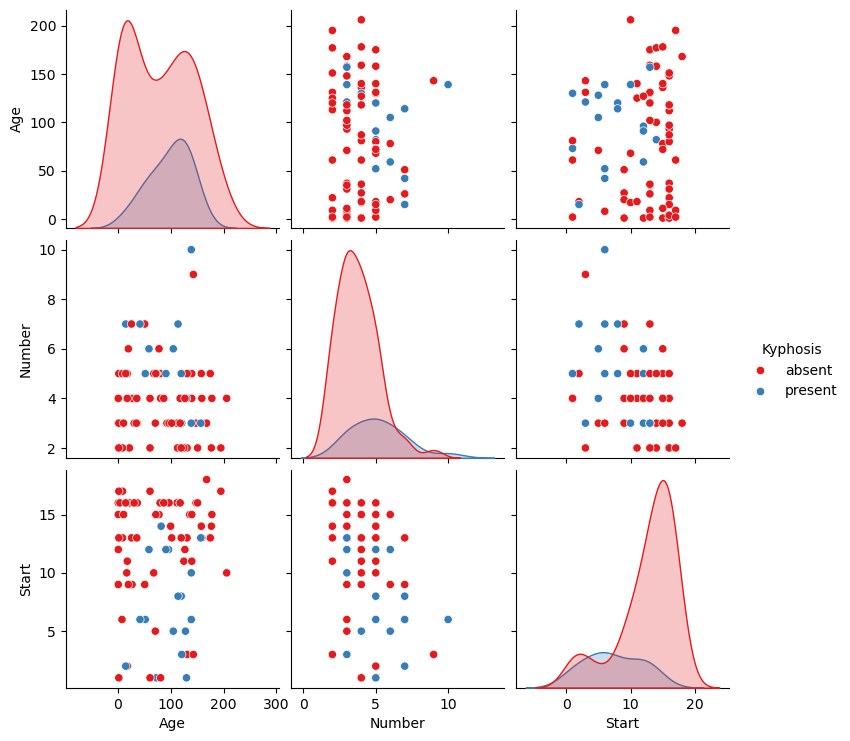

In [6]:
sns.pairplot(df, hue='Kyphosis', palette='Set1')

## Train and Test

In [7]:
from sklearn.model_selection import train_test_split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(df.drop(columns='Kyphosis',axis=1),df['Kyphosis'], test_size=0.3)

In [9]:
from sklearn.tree import DecisionTreeClassifier 

In [10]:
dtree = DecisionTreeClassifier()

In [11]:
dtree.fit(X_train,y_train)

DecisionTreeClassifier()

## Prediction and Evaluation 

In [12]:
from sklearn.metrics import confusion_matrix, classification_report

In [13]:
pred = dtree.predict(X_test)

In [14]:
print(confusion_matrix(y_test,pred))

[[13  6]
 [ 2  4]]


In [15]:
print(classification_report(y_test,pred))

              precision    recall  f1-score   support

      absent       0.87      0.68      0.76        19
     present       0.40      0.67      0.50         6

    accuracy                           0.68        25
   macro avg       0.63      0.68      0.63        25
weighted avg       0.75      0.68      0.70        25



## Tree Visualization

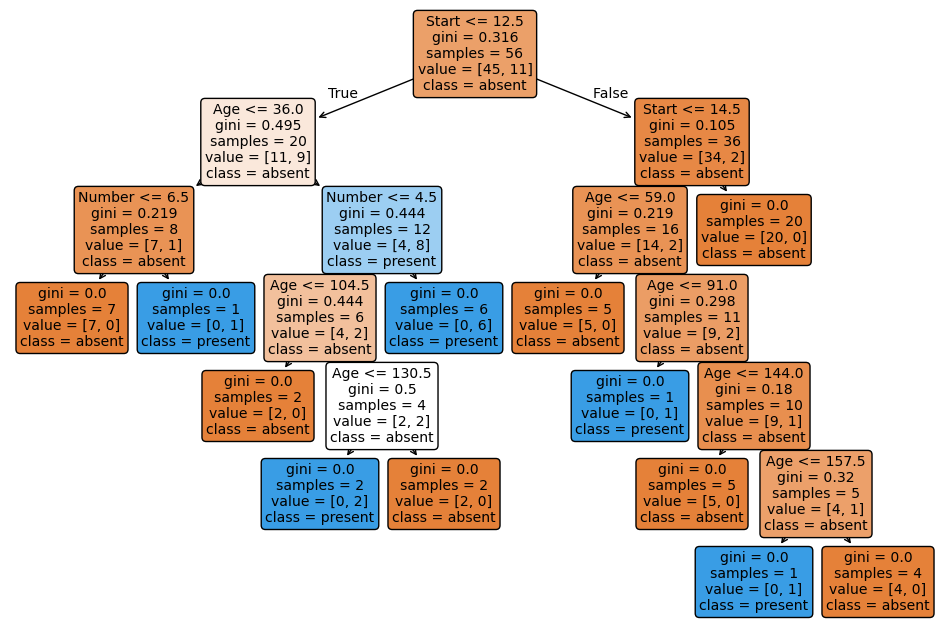

In [20]:
from sklearn.tree import plot_tree

plt.figure(figsize=(12, 8))
plot_tree(
    dtree, 
    feature_names=list(df.columns[1:]), 
    class_names=['absent', 'present'], 
    filled=True,
    rounded=True
)
plt.show()

## Random Forests

In [21]:
from sklearn.ensemble import RandomForestClassifier
rfc = RandomForestClassifier(n_estimators=100)
rfc.fit(X_train, y_train)

RandomForestClassifier()

In [22]:
rfc_pred = rfc.predict(X_test)

In [23]:
print(confusion_matrix(y_test,rfc_pred))

[[16  3]
 [ 4  2]]


In [24]:
print(classification_report(y_test,rfc_pred))

              precision    recall  f1-score   support

      absent       0.80      0.84      0.82        19
     present       0.40      0.33      0.36         6

    accuracy                           0.72        25
   macro avg       0.60      0.59      0.59        25
weighted avg       0.70      0.72      0.71        25



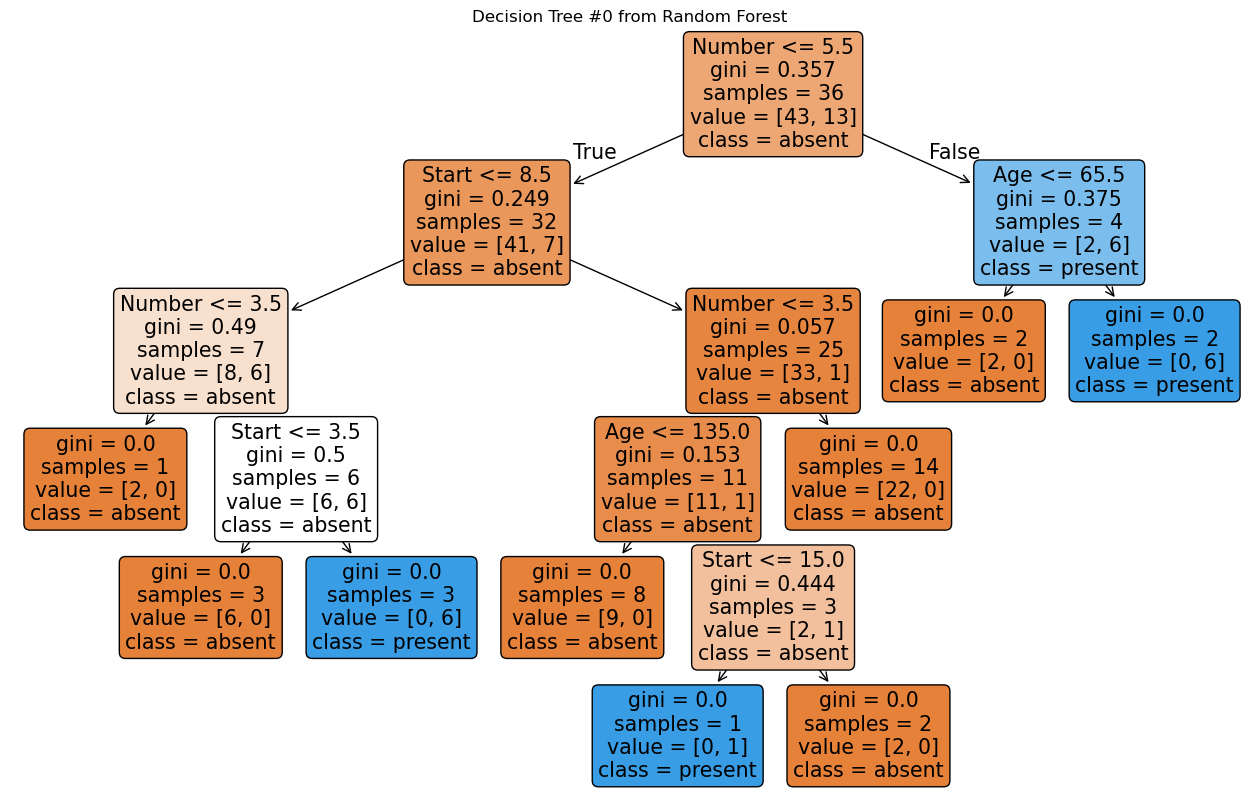

In [25]:


# Choose which tree you want to look at (e.g., the very first tree at index 0)
tree_index = 0

plt.figure(figsize=(16, 10))
plot_tree(
    rfc.estimators_[tree_index], 
    feature_names=list(df.columns[1:]), 
    class_names=['absent', 'present'], 
    filled=True,
    rounded=True
)
plt.title(f"Decision Tree #{tree_index} from Random Forest")
plt.show()